# Modelagem
### 0. Imports e leitura do dataset

In [85]:
import pandas as pd
import numpy as np
import nltk
from nltk.corpus import stopwords
from sklearn.model_selection import (
    train_test_split, StratifiedKFold, cross_val_score,
    cross_validate, GridSearchCV
)
from sklearn.metrics import f1_score, accuracy_score
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_sample_weight
from xgboost import XGBClassifier
import optuna
from optuna.trial import TrialState
from sentence_transformers import SentenceTransformer
from sklearn.pipeline import Pipeline
from sklearn.base import clone
import joblib
from pathlib import Path

RANDOM_STATE = 42

In [86]:
df = pd.read_csv('../data/processed/df_02.csv')
print(df.shape)
df.head()

(12530, 2)


,frase,rotulo
0,Ainda estou esperando pelo meu cartão?,chegada_do_cartão
1,O que posso fazer se meu cartão ainda não cheg...,chegada_do_cartão
2,Eu tenho esperado por mais de uma semana. O ca...,chegada_do_cartão
3,Posso rastrear meu cartão enquanto está em pro...,chegada_do_cartão
4,"Como eu posso saber se vou receber meu cartão,...",chegada_do_cartão


### 1. Divisão treino e teste
Divisão estratificada pelo `rotulo` (80% treino / 20% teste), para os dois conjuntos manterem a mesma proporção de cada classe.

In [87]:
X = df['frase']
y = df['rotulo']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=RANDOM_STATE,
)

print(f'Treino: {X_train.shape[0]} frases')
print(f'Teste: {X_test.shape[0]} frases')

Treino: 10024 frases
Teste: 2506 frases


In [88]:
# Conferindo se a proporção de cada rótulo se manteve nos dois conjuntos
proporcoes = pd.DataFrame({
    'total': y.value_counts(normalize=True),
    'treino': y_train.value_counts(normalize=True),
    'teste': y_test.value_counts(normalize=True),
}).round(4)

print(f"Rótulos no treino: {y_train.nunique()} | no teste: {y_test.nunique()}")
proporcoes.head(10)

Rótulos no treino: 77 | no teste: 77


,total,treino,teste
rotulo,,,
aceitação_de_cartão,0.0075,0.0075,0.0076
alterar_pin,0.0125,0.0125,0.0124
apple_pay_ou_google_pay,0.0126,0.0126,0.0128
ativar_meu_cartão,0.0148,0.0149,0.0148
beneficiário_não_permitido,0.0152,0.0153,0.0152
cancelar_transferência,0.0152,0.0152,0.0152
cartão_comprometido,0.0100,0.0100,0.0100
cartão_engolido,0.0076,0.0076,0.0076
cartão_não_funcionando,0.0109,0.0110,0.0108


### 2. Representações do texto
Para a modelagem, no treino dos modelos, usarei a representação das frases em `TF-IDF` e em `Embeddings`:


- **Definição TF-IDF (Como explicado no notebook anterior):** \
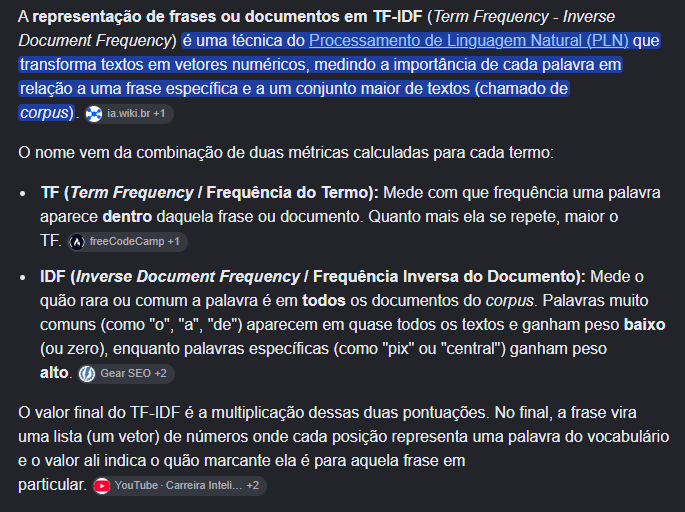

A ideia é dar um peso alto para uma palavra se ela for frequente em um documento e rara nos demais, e peso baixo se aparecer em quase todos, como as stopwords.

- **Definição Embeddings:** \
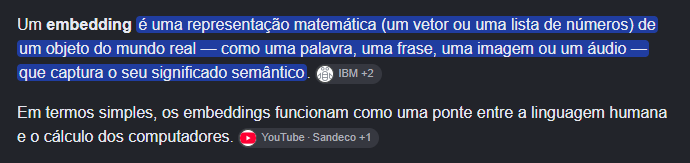

Esses vetores são construídos de modo que textos com significados parecidos fiquem próximos no espaço vetorial, mesmo quando usam palavras diferentes. No caso desse projeto, onde usarei embeddings de frases, o modelo lê a frase inteira e gera um único vetor para ela, levando em conta o contexto e a ordem das palavras. Diferente do TF-IDF, que depende da contagem de termos, essa representação capta relações semânticas, como sinônimos e paráfrases. Isso permite que classificadores simples, como a regressão logística, separem as intenções com base no significado das frases.
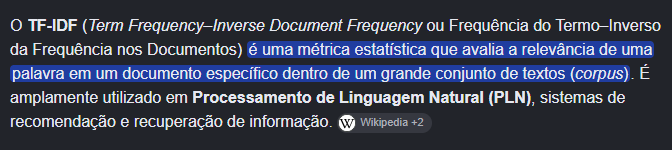
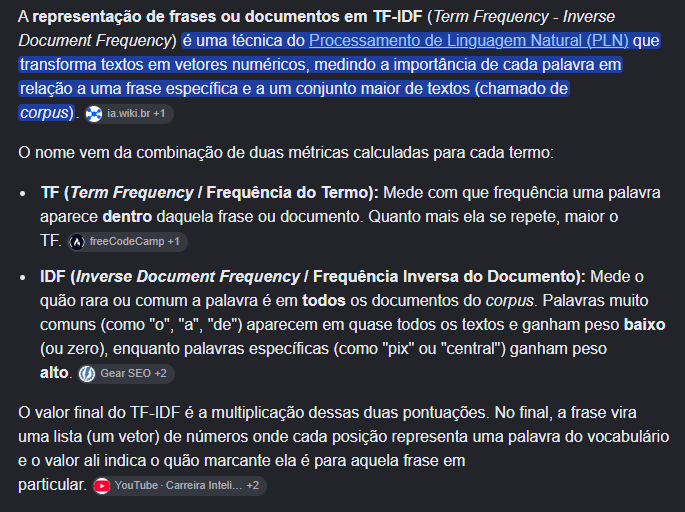

**Conjuntos utilizados**

Para a representação `TF-IDF`, testarei uma série de conjuntos (com GridSearch) para ver qual performa melhor, e registrarei aquele que obter melhor resultado.

Já para os `Embeddings`, vou comparar 3 encoders diferentes e registrar qual performa melhor:
- Serafim 335m, treinado apenas com palavras em português
- multilingual-e5-base, treino com multiplas linguas, mas com tamanho pequeno-médio
- multilingual-e5-large, mesmo modelo anterior, com tamanho maior


| Representação | Tipo                                    | O que a comparação isola            |
|---|-----------------------------------------|-------------------------------------|
| TF-IDF | esparsa                                 | efeito de ajuste de hiperparâmetros |
| Serafim 335m | embedding, em português | português vs. multilíngue (vs. e5)  |
| multilingual-e5-base | embedding, multilíngue                  | baseline de tamanho para o e5-large |
| multilingual-e5-large | embedding, multilíngue                  | efeito do tamanho do modelo (vs. e5-base) |

#### 2.1 TF-IDF com e sem stopwords
A lista de stopwords é a mesma do notebook 2, sem as negações (`não`, `nem`, `sem`), pois elas podem inverter o sentido das frases.

o TF-IDF é aprendido no treino e apenas aplicados no teste, para não haver data leakage.

In [89]:
# importando stopwords e removendo as negações
nltk.download('stopwords', quiet=True)

negacoes = {'não', 'nem', 'sem'}
stop_pt = set(stopwords.words('portuguese')) - negacoes

In [90]:
# Definindo treino e teste em formato TF-IDF, com e sem stopwords
# token_pattern mantém palavras de 1 caractere (o, a, é, 1), como no notebook 2
tfidf_com_stopw = TfidfVectorizer(token_pattern=r'(?u)\b\w+\b')
X_train_tfidf = tfidf_com_stopw.fit_transform(X_train)
X_test_tfidf = tfidf_com_stopw.transform(X_test)

tfidf_sem_stopw = TfidfVectorizer(token_pattern=r'(?u)\b\w+\b', stop_words=sorted(stop_pt))
X_train_tfidf_sem_stopw = tfidf_sem_stopw.fit_transform(X_train)
X_test_tfidf_sem_stopw = tfidf_sem_stopw.transform(X_test)

print('Vocabulário com stopwords:', len(tfidf_com_stopw.vocabulary_))
print('Vocabulário sem stopwords:', len(tfidf_sem_stopw.vocabulary_))

Vocabulário com stopwords: 3097
Vocabulário sem stopwords: 2966


#### 2.2 Embeddings
Os modelos codificadores de embeddings que vou usar são:
- **Serafim 335m**: modelo treinado em português. Não usa prefixo nas frases.
- **multilingual-e5-base** e **multilingual-e5-large**: modelos multilingue. Ambos recebem o prefixo `"query: "` nas frases, pois esses modelos foram treinados com prefixos que indicam o papel de cada texto (`"query: "` para perguntas e `"passage: "` para documentos). Assim, os autores recomendam usar `"query: "` em todas as frases em tarefas de classificação.

Usarei as frases sem remover stopwords, pois esses modelos foram treinados com texto natural. Os vetores são normalizados (norma 1).

Como gerar os embeddings demora muito, vou salvá-los em `data/embeddings/` com os índices do treino e do teste. Se a divisão mudar (outro `random_state`, por exemplo), os embeddings são gerados de novo.

In [91]:
# Definição do nome e link de import dos embeddings
MODELOS_EMBEDDING = {
    'serafim_335m': {'nome': 'PORTULAN/serafim-335m-portuguese-pt-sentence-encoder', 'prefixo': ''},
    'e5_base': {'nome': 'intfloat/multilingual-e5-base', 'prefixo': 'query: '},
    'e5_large': {'nome': 'intfloat/multilingual-e5-large', 'prefixo': 'query: '},
}

PASTA_EMBEDDINGS = Path('../data/embeddings')
PASTA_EMBEDDINGS.mkdir(parents=True, exist_ok=True)

In [92]:
# Gera os embeddings de treino e teste de um modelo, ou carrega do disco se já existirem para a mesma divisão
def gerar_embeddings(chave, nome, prefixo, batch_size=32):
    arquivo = PASTA_EMBEDDINGS / f'{chave}.npz'

    if arquivo.exists():
        salvo = np.load(arquivo)
        mesma_divisao = (np.array_equal(salvo['idx_train'], X_train.index.values)
                         and np.array_equal(salvo['idx_test'], X_test.index.values))
        if mesma_divisao:
            print(f'{chave}: carregado de {arquivo}')
            return salvo['train'], salvo['test']
        print(f'{chave}: divisão diferente da salva, gerando de novo')

    modelo = SentenceTransformer(nome)
    def codificar(frases):
        return modelo.encode([prefixo + f for f in frases], batch_size=batch_size,
                             normalize_embeddings=True, show_progress_bar=True)

    emb_train = codificar(X_train)
    emb_test = codificar(X_test)

    np.savez(arquivo, train=emb_train, test=emb_test,
             idx_train=X_train.index.values, idx_test=X_test.index.values)
    print(f'{chave}: salvo em {arquivo}')
    return emb_train, emb_test

In [93]:
embeddings = {}
for chave, config in MODELOS_EMBEDDING.items():
    embeddings[chave] = gerar_embeddings(chave, config['nome'], config['prefixo'])

serafim_335m: carregado de ..\data\embeddings\serafim_335m.npz
e5_base: carregado de ..\data\embeddings\e5_base.npz
e5_large: carregado de ..\data\embeddings\e5_large.npz


#### 2.3 Conjunto de representações
Coloco todas as representações num único dicionário `{nome do conjunto : (X_train, X_test),}`

In [94]:
representacoes = {
    'tfidf_com_stopwords': (X_train_tfidf, X_test_tfidf),
    'tfidf_sem_stopwords': (X_train_tfidf_sem_stopw, X_test_tfidf_sem_stopw),
    **embeddings,
}

pd.DataFrame(
    [(nome, tr.shape[0], te.shape[0], tr.shape[1]) for nome, (tr, te) in representacoes.items()],
    columns=['representação', 'frases treino', 'frases teste', 'dimensões'],
)

,representação,frases treino,frases teste,dimensões
0,tfidf_com_stopwords,10024,2506,3097
1,tfidf_sem_stopwords,10024,2506,2966
2,serafim_335m,10024,2506,1024
3,e5_base,10024,2506,768
4,e5_large,10024,2506,1024


### 3. Baseline: TF-IDF + Regressão Logística sem ajuste
Crio um modelo baseline que será o ponto de referência para comparação de performance dos próximos modelos. Escolhi que esse baseline será:

**Regressão Logística sem ajuste de hiperparâmetros + TF-IDF apenas de unigramas, com stopwords**

#### 3.1 Tabela de resultados
Definição de funçôes reutilizáveis de registro da performance de cada um dos modelos em uma tabela.

Todos os modelos avaliados são registrados tendo o baseline como referência. A coluna `ganho_f1_pp` mostra o ganho de cada modelo em pontos percentuais de F1-macro sobre o baseline. A coluna `f1_macro_cv` mostra o F1-macro na validação cruzada, que é o número usado para escolher cada modelo, ao lado do F1-macro no teste.

In [95]:
BASELINE = ('Regressão Logística (baseline)', 'TF-IDF')

resultados = {}

# Registra (ou substitui) o resultado de um modelo no teste
# f1_cv é o F1-macro do modelo na validação cruzada (o best_score_ da busca)
def registrar_resultado(modelo, representacao, y_true, y_pred, f1_cv=None):
    resultados[(modelo, representacao)] = {
        'modelo': modelo,
        'representação': representacao,
        'acurácia': accuracy_score(y_true, y_pred),
        'f1_macro_cv': f1_cv,
        'f1_macro': f1_score(y_true, y_pred, average='macro'),
    }

# Monta a tabela ordenada por F1-macro, com o ganho de cada modelo sobre o baseline
def tabela_resultados():
    tabela = pd.DataFrame(resultados.values())
    f1_baseline = resultados[BASELINE]['f1_macro']
    tabela['ganho_f1_pp'] = (tabela['f1_macro'] - f1_baseline) * 100
    return (tabela.sort_values('f1_macro', ascending=False)
                  .reset_index(drop=True)
                  .round({'acurácia': 4, 'f1_macro_cv': 4, 'f1_macro': 4, 'ganho_f1_pp': 2}))

#### 3.2 Treino e avaliação

In [96]:
baseline_log_reg = LogisticRegression(max_iter=1000, C=1)
baseline_log_reg.fit(X_train_tfidf, y_train)
y_pred_baseline = baseline_log_reg.predict(X_test_tfidf)

print('Iterações até convergir:', baseline_log_reg.n_iter_[0])

Iterações até convergir: 36


In [97]:
# F1-macro do baseline na validação cruzada, com os mesmos folds das buscas da seção 4
# o TF-IDF fica dentro do pipeline para ser aprendido só com os folds de treino
cv_estratificado = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

pipeline_baseline = Pipeline([
    ('tfidf', TfidfVectorizer(token_pattern=r'(?u)\b\w+\b')),
    ('clf', LogisticRegression(max_iter=1000, C=1)),
])

f1_cv_baseline = cross_val_score(pipeline_baseline, X_train, y_train, cv=cv_estratificado, scoring='f1_macro').mean()
print('F1-macro do baseline (CV):', round(f1_cv_baseline, 4))

F1-macro do baseline (CV): 0.8441


In [98]:
registrar_resultado(*BASELINE, y_test, y_pred_baseline, f1_cv_baseline)
tabela_resultados()

,modelo,representação,acurácia,f1_macro_cv,f1_macro,ganho_f1_pp
0,Regressão Logística (baseline),TF-IDF,0.8671,0.8441,0.8654,0.0


### 4. TF-IDF


 #### 4.1 Busca de hiperparâmetros

Os hiperparâmetros serão escolhidos com `GridSearchCV` usando apenas o conjunto de treino, com validação cruzada estratificada com 5 folds e F1-macro como critério de escolha. A exceção é o XGBoost (4.4.2), que usa `Optuna` com os mesmos folds e o mesmo critério.

In [99]:
# Função reutilizável para aplicar GridSearch nos classificadores
# Cada resultado é salvo em ../data/buscas, com joblib (comprimido, pois as florestas da 4.4 ocupam alguns GB)
# Se o resultado já existir (mesmo grid e mesma divisão), a função carrega os resultados da pasta buscas pelo nome 'arquivo'

def buscar(pipeline, arquivo, n_jobs, grade):
    arquivo = Path(arquivo)

    if arquivo.exists():
        salvo = joblib.load(arquivo)
        mesmo_grid = salvo['busca'].param_grid == grade
        mesma_divisao = np.array_equal(salvo['idx_train'], X_train.index.values)
        if mesmo_grid and mesma_divisao:
            busca = salvo['busca']
            print(f'Carregado de {arquivo}')
            print('Melhores parâmetros:', busca.best_params_)
            print('Melhor F1-macro (CV):', round(busca.best_score_, 4))
            return busca
        print(f'Grid ou divisão diferentes do salvo em {arquivo}, rodando de novo')

    busca = GridSearchCV(
        pipeline,
        param_grid=grade,
        cv=cv_estratificado,
        scoring=['accuracy', 'precision_macro', 'recall_macro', 'f1_macro'],
        refit='f1_macro',
        n_jobs=n_jobs,
        verbose=1,
    )
    busca.fit(X_train, y_train)

    joblib.dump({'busca': busca, 'idx_train': X_train.index.values}, arquivo, compress=3)
    print(f'Salvo em {arquivo}')
    print('Melhores parâmetros:', busca.best_params_)
    print('Melhor F1-macro (CV):', round(busca.best_score_, 4))
    return busca

#### 4.2 Regressão Logística + TF-IDF
Aqui, testo as combinações:
- **n-gramas:** só unigramas, uni + bigramas ou uni + bi + trigramas.
- **Stopwords:** mantidas ou removidas (lista de remoção mantém as negações).
- **`min_df`:** a palavra precisa aparecer em pelo menos 1 ou 2 frases para entrar no vocabulário.
- **`sublinear_tf`:** com ou sem a troca do TF por 1 + ln(TF), que reduz o peso de palavras repetidas na mesma frase.
- **`class_weight`:** sem balanceamento de classes ou com, que dá mais peso aos erros nas classes com menos frases.
- **C (regularização):** valores [0.1, 1, 10 e 100] fixos. É o inverso da força de regularização (valores menores = mais regularização).
    - **Regra:** Se o melhor C ficar no limite da grade (0.1 ou 100), faço uma segunda busca variando só o C, com os demais hiperparâmetros fixos, para ver se valores além desse limite são melhores.

Observações:
- Não usarei StandardScaler porque o TF-IDF já define o peso certo de cada palavra. Usá-lo distorceria esses pesos.
- Após a busca dos hiperparâmetros, testarei regularização L1 e L2.

In [100]:
# 4.1 TF-IDF + Regressão Logística

pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(token_pattern=r'(?u)\b\w+\b')),  # fixo
    ('clf', LogisticRegression(max_iter=1000)),
])

grade_tfidf = {
    'tfidf__ngram_range': [(1, 1), (1, 2), (1, 3)],
    'tfidf__stop_words': [None, sorted(stop_pt)],
    'tfidf__min_df': [1, 2],
    'tfidf__sublinear_tf': [False, True],
    'clf__C': [0.1, 1, 10, 100],
    'clf__class_weight': [None, 'balanced']

}

busca_reglog = buscar(
    pipeline,
    '../data/buscas/reglog_tfidf.joblib',
    n_jobs=3, grade=grade_tfidf)

Carregado de ..\data\buscas\reglog_tfidf.joblib
Melhores parâmetros: {'clf__C': 10, 'clf__class_weight': 'balanced', 'tfidf__min_df': 1, 'tfidf__ngram_range': (1, 1), 'tfidf__stop_words': None, 'tfidf__sublinear_tf': True}
Melhor F1-macro (CV): 0.8756


#### Teste de regularização
Aplico regularização utilizando os melhores hiperparâmetros encontrados no GridSearch do passo anterior para ver se há melhora de performance

In [101]:
pipeline_penalty = Pipeline([
    ('tfidf', TfidfVectorizer(token_pattern=r'(?u)\b\w+\b')),
    ('clf', LogisticRegression(solver='saga', max_iter=5000)),
])

grade_penalty = {
    'tfidf__ngram_range': [busca_reglog.best_params_['tfidf__ngram_range']],
    'tfidf__stop_words': [busca_reglog.best_params_['tfidf__stop_words']],
    'tfidf__min_df': [busca_reglog.best_params_['tfidf__min_df']],
    'tfidf__sublinear_tf': [busca_reglog.best_params_['tfidf__sublinear_tf']],
    'clf__class_weight': ['balanced'],
    'clf__l1_ratio': [0, 1],          # 0 = L2, 1 = L1
    'clf__C': [1, 10, 100],
}

busca_penalty = buscar(
    pipeline_penalty,
    '../data/buscas/reglog_tfidf_penalty.joblib',
    n_jobs=3,
    grade=grade_penalty,
)

Carregado de ..\data\buscas\reglog_tfidf_penalty.joblib
Melhores parâmetros: {'clf__C': 10, 'clf__class_weight': 'balanced', 'clf__l1_ratio': 0, 'tfidf__min_df': 1, 'tfidf__ngram_range': (1, 1), 'tfidf__stop_words': None, 'tfidf__sublinear_tf': True}
Melhor F1-macro (CV): 0.8749


##### Não houve ganho de performance com a regularização. Por isso, vou seguir com o modelo sem L1 ou L2.

In [102]:
REGLOG_TFIDF = ('Regressão Logística ajustada', 'TF-IDF')

#### 4.3 LinearSVC + TF-IDF
Uso a mesma grade de TF-IDF da Regressão Logística, para que a comparação entre os dois modelos isole apenas o efeito do classificador:
- **n-gramas:** só unigramas, uni + bigramas ou uni + bi + trigramas.
- **Stopwords:** mantidas ou removidas (lista de remoção mantém as negações).
- **`min_df`:** a palavra precisa aparecer em pelo menos 1 ou 2 frases para entrar no vocabulário.
- **`sublinear_tf`:** com ou sem a troca do TF por 1 + ln(TF), que reduz o peso de palavras repetidas na mesma frase.
- **`class_weight`:** sem balanceamento de classes ou com, que dá mais peso aos erros nas classes com menos frases.
- **C (regularização):** valores [0.01, 0.1, 1 e 10]. Assim como na Regressão Logística, é o inverso da força de regularização (valores menores = margem mais larga e mais regularização). A grade começa mais baixa porque, no SVM, o melhor C com TF-IDF costuma ser menor.
    - **Regra:** Se o melhor C ficar no limite da grade (0.01 ou 10), faço uma segunda busca variando só o C, com os demais hiperparâmetros fixos, para ver se valores além desse limite são melhores.

Observações:
- Uso o kernel linear porque o TF-IDF gera vetores esparsos com milhares de dimensões. Nesse espaço as classes já costumam ser separáveis por um hiperplano, e os kernels RBF e polinomial raramente trazem ganho, além de serem bem mais lentos.
- Uso o `LinearSVC` em vez do `SVC(kernel='linear')`. O `LinearSVC` treina um classificador por classe (um contra todos, 77 modelos). O `SVC` treina um por par de classes (um contra um, 2.926 modelos), o que o torna bem mais lento com resultados praticamente iguais.
- `max_iter=5000` para garantir a convergência, principalmente com valores altos de C.
- Também não uso StandardScaler aqui, pelo mesmo motivo da Regressão Logística.

In [103]:
# 4.3 SVM + TF-IDF

pipeline_svm = Pipeline([
    ('tfidf', TfidfVectorizer(token_pattern=r'(?u)\b\w+\b')),  # fixo
    ('clf', SVC(cache_size=1000)),
])

grade_svm = [
    {
        'tfidf__ngram_range': [(1, 1), (1, 2), (1, 3)],
        'tfidf__stop_words': [None, sorted(stop_pt)],
        'tfidf__min_df': [1, 2],
        'tfidf__sublinear_tf': [False, True],
        'clf__kernel': ['linear'],
        'clf__C': [0.01, 0.1, 1, 10, 100],
        'clf__class_weight': [None, 'balanced']
    },
    {
        'tfidf__ngram_range': [(1, 1), (1, 2), (1, 3)],
        'tfidf__stop_words': [None, sorted(stop_pt)],
        'tfidf__min_df': [1, 2],
        'tfidf__sublinear_tf': [False, True],
        'clf__kernel': ['rbf'],
        'clf__C': [0.1, 1, 10, 100],
        'clf__gamma': ['scale', 0.1, 1, 10],
        'clf__class_weight': [None, 'balanced']
    },
    {
        'tfidf__ngram_range': [(1, 1), (1, 2), (1, 3)],
        'tfidf__stop_words': [None, sorted(stop_pt)],
        'tfidf__min_df': [1, 2],
        'tfidf__sublinear_tf': [False, True],
        'clf__kernel': ['poly'],
        'clf__C': [0.1, 1, 10, 100],
        'clf__degree': [2, 3],
        'clf__coef0': [0, 1],
        'clf__gamma': [1],
        'clf__class_weight': [None, 'balanced']
    },
]

busca_svm = buscar(
    pipeline_svm,
    '../data/buscas/svc_tfidf.joblib',
    n_jobs=6, grade=grade_svm)

Carregado de ..\data\buscas\svc_tfidf.joblib
Melhores parâmetros: {'clf__C': 1, 'clf__class_weight': 'balanced', 'clf__coef0': 1, 'clf__degree': 2, 'clf__gamma': 1, 'clf__kernel': 'poly', 'tfidf__min_df': 1, 'tfidf__ngram_range': (1, 1), 'tfidf__stop_words': None, 'tfidf__sublinear_tf': True}
Melhor F1-macro (CV): 0.883


In [104]:
SVM_TFIDF = ('SVM ajustado', 'TF-IDF')

#### 4.4 Ensembles + TF-IDF
Nesta seção, decidi treinar modelos de ensemble baseados em árvores de decisão. Porém, o resultado esperado não é dos melhores, devido à forma como as árvores lidam com o TF-IDF.

O TF-IDF gera uma matriz esparsa, em que cada frase (linha) tem poucas palavras com valor diferente de 0, entre outras milhares de colunas, e cada palavra ajuda a indicar a classe. Os modelos lineares dão um peso para cada palavra em cada classe. Para classificar uma frase, eles somam os pesos de todas as palavras dela e escolhem a classe com a maior soma.

As árvores, por outro lado, dividem os dados olhando uma palavra por vez. Por isso, precisam de muitas divisões para chegar ao mesmo resultado. Como temos 77 classes, com poucas frases cada, as frases vão sendo separadas em grupos cada vez menores a cada divisão. No fim, sobram poucas frases em cada folha, e a árvore não tem exemplos suficientes para aprender o que cada palavra indica.

**Modelos escolhidos:**
- **Random Forest (Bagging):** treina várias árvores independentes, cada uma com uma amostra bootstrap das frases e um sorteio de palavras candidatas em cada divisão. A previsão final é o voto das árvores. A média de árvores diferentes reduz a variância de uma árvore sozinha.
- **XGBoost (Boosting):** treina as árvores em sequência, e cada nova árvore corrige os erros das anteriores. Reduz o viés, mas tem mais hiperparâmetros e é mais sensível a eles.

Observações:
- Para esses modelos, usarei a melhor configuração de hiperparâmetros do TF-IDF nos treinos da RegLog e do SVM (as duas buscas chegaram à mesma).
- Não uso StandardScaler, pois as árvores não dependem da escala das features.

In [105]:
# TF-IDF fixo na melhor configuração da busca do SVM e Regressão Logística
tfidf_fixo = {
    'tfidf__ngram_range': busca_svm.best_params_['tfidf__ngram_range'],
    'tfidf__stop_words': busca_svm.best_params_['tfidf__stop_words'],
    'tfidf__min_df': busca_svm.best_params_['tfidf__min_df'],
    'tfidf__sublinear_tf': busca_svm.best_params_['tfidf__sublinear_tf'],
}
tfidf_fixo

{'tfidf__ngram_range': (1, 1),
 'tfidf__stop_words': None,
 'tfidf__min_df': 1,
 'tfidf__sublinear_tf': True}

#### Random Forest + TF-IDF
Testo as combinações:
- **`max_features`:** quantas palavras são sorteadas como candidatas em cada divisão: `log2` ≈ 12, `sqrt` ≈ 56. Menos candidatas deixam as árvores mais diferentes entre si, e mais candidatas deixam cada árvore mais forte.
- **`min_samples_leaf`:** número mínimo de frases em cada folha: 1, 2 ou 4. Valores maiores deixam as árvores menores.
- **`class_weight`:** sem balanceamento de classes, `balanced` (pesos calculados no treino inteiro) ou `balanced_subsample` (pesos recalculados na amostra bootstrap de cada árvore).
    - **Regra:** Se o melhor `max_features` ficar no limite da grade (`log2` ou 5%), faço uma segunda busca variando só ele, com os demais hiperparâmetros fixos, para ver se valores além desse limite são melhores.

Observações:
- `n_estimators=300` fixo. Mais árvores não causam overfitting, só aumentam o tempo, e a partir de algumas centenas o ganho é pequeno.
- Não limito o `max_depth`. O tamanho das árvores já será controlado pelo `min_samples_leaf`.

In [106]:
# 4.4.1 Random Forest + TF-IDF

pipeline_rf = Pipeline([
    ('tfidf', TfidfVectorizer(token_pattern=r'(?u)\b\w+\b')),  # fixo
    ('clf', RandomForestClassifier(n_estimators=300, n_jobs=10, random_state=RANDOM_STATE)),
])

grade_rf = {
    'tfidf__ngram_range': [tfidf_fixo['tfidf__ngram_range']],
    'tfidf__stop_words': [tfidf_fixo['tfidf__stop_words']],
    'tfidf__min_df': [tfidf_fixo['tfidf__min_df']],
    'tfidf__sublinear_tf': [tfidf_fixo['tfidf__sublinear_tf']],
    'clf__max_features': ['log2', 'sqrt'],
    'clf__min_samples_leaf': [1, 2, 4],
    #'max_depth': [None, 5, 10],
    'clf__class_weight': [None, 'balanced'],
}

busca_rf = buscar(
    pipeline_rf,
    '../data/buscas/rf_tfidf.joblib',
    n_jobs=1, grade=grade_rf)

Carregado de ..\data\buscas\rf_tfidf.joblib
Melhores parâmetros: {'clf__class_weight': 'balanced', 'clf__max_features': 'log2', 'clf__min_samples_leaf': 1, 'tfidf__min_df': 1, 'tfidf__ngram_range': (1, 1), 'tfidf__stop_words': None, 'tfidf__sublinear_tf': True}
Melhor F1-macro (CV): 0.8487


In [107]:
RF_TFIDF = ('Random Forest ajustado', 'TF-IDF')

#### XGBoost + TF-IDF (com Optuna)
Como o XGBoost tem muitos hiperparâmetros contínuos, o treino usando GridSearch dariam muitas combinações e custaria muito tempo. Por isso, usarei o `Optuna` para esse ajuste.

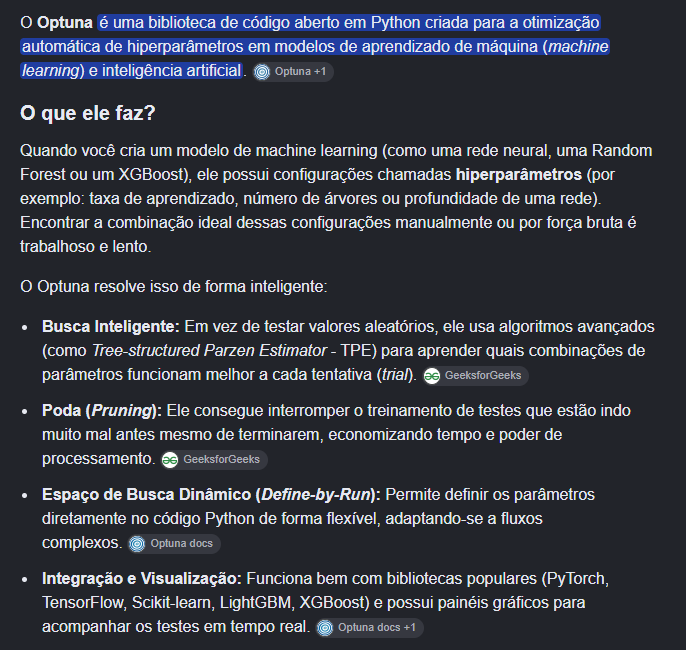

Testarei as faixas:
- **`n_estimators`:** número de rodadas de boosting, de 100 a 400.
- **`learning_rate`:** quanto cada árvore corrige das anteriores, de 0,03 a 0,3 (escala log). Valores menores precisam de mais rodadas.
- **`max_depth`:** profundidade máxima de cada árvore, de 3 a 8.
- **`min_child_weight`:** soma mínima da hessiana (o "peso" das frases) em cada folha, de 0,01 a 2 (escala log).
- **`subsample`:** fração das frases sorteada para cada rodada, de 0,6 a 1.
- **`colsample_bytree`:** fração das palavras sorteada para cada árvore, de 0,3 a 1.
- **`reg_lambda` e `reg_alpha`:** regularização L2 e L1 dos pesos das folhas, de 0,001 a 10 (escala log).
- **Balanceamento:** sem ou com pesos por classe, equivalente ao `class_weight`.

Observações:
- O XGBoost não tem `class_weight`. O equivalente ao `balanced` é passar um peso para cada frase com `compute_sample_weight('balanced', y)` no `fit`.
- O XGBoost exige rótulos inteiros (0 a 76), então codifico os rótulos com `LabelEncoder` e decodifico as previsões no final.
- A faixa do `min_child_weight` começa bem abaixo do padrão (1). Com 77 classes, a probabilidade inicial de cada classe é ~1/77, e a hessiana de cada frase fica perto de 0,013. Com `min_child_weight=1`, cada folha precisaria de ~80 frases, quase todas as frases de uma classe em um fold, o que trava as divisões.
- O `n_estimators` entra na busca, em vez de usar early stopping, porque parar o treino com o fold de validação e depois avaliar no mesmo fold inflaria o F1-macro.
- As tentativas rodam em sequência, com o paralelismo dentro do XGBoost (`n_jobs=10`), e o amostrador tem semente fixa, para a busca ser reprodutível.
- `tree_method='hist'` aceita direto a matriz esparsa do TF-IDF.
- Assim como a `buscar`, a `buscar_optuna` salva o estudo em `../data/buscas` com joblib, mas a cada tentativa. A busca leva algumas horas, então pode ser interrompida e continua de onde parou. Depois da busca, o modelo final é treinado no treino inteiro com os melhores hiperparâmetros (o equivalente ao `refit` do GridSearch) e salvo junto.

In [108]:
# Função reutilizável para aplicar Optuna nos classificadores, no mesmo formato da buscar
# O estudo é salvo em ../data/buscas, com joblib, a cada tentativa
# Se o arquivo já existir (mesma divisão), carrega o estudo e só roda as tentativas que faltam para chegar em n_tentativas
# ajustar_final recebe os melhores hiperparâmetros e devolve o modelo treinado no treino inteiro

def buscar_optuna(objetivo, ajustar_final, arquivo, n_tentativas):
    arquivo = Path(arquivo)
    estudo, modelo = None, None

    if arquivo.exists():
        salvo = joblib.load(arquivo)
        if np.array_equal(salvo['idx_train'], X_train.index.values):
            estudo, modelo = salvo['estudo'], salvo['modelo']
            print(f'Carregado de {arquivo}')
        else:
            print(f'Divisão diferente da salva em {arquivo}, rodando de novo')

    if estudo is None:
        estudo = optuna.create_study(
            direction='maximize',
            sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE),
            pruner=optuna.pruners.MedianPruner(n_startup_trials=8),
        )

    def salvar(estudo, modelo=None):
        joblib.dump({'estudo': estudo, 'modelo': modelo, 'idx_train': X_train.index.values}, arquivo, compress=3)

    feitas = len(estudo.get_trials(states=(TrialState.COMPLETE, TrialState.PRUNED)))
    if feitas < n_tentativas:
        modelo = None  # o melhor resultado pode mudar, então o modelo final é treinado de novo
        estudo.optimize(objetivo, n_trials=n_tentativas - feitas,
                        callbacks=[lambda estudo, tentativa: salvar(estudo)])

    if modelo is None:
        modelo = ajustar_final(estudo.best_params)
        salvar(estudo, modelo)
        print(f'Salvo em {arquivo}')

    podadas = len(estudo.get_trials(states=(TrialState.PRUNED,)))
    print(f'Tentativas: {len(estudo.trials)} ({podadas} podadas)')
    print('Melhores parâmetros:', estudo.best_params)
    print('Melhor F1-macro (CV):', round(estudo.best_value, 4))
    return estudo, modelo

In [109]:
# 4.4.2 XGBoost + TF-IDF

# O XGBoost exige rótulos inteiros (0 a 76)
codificador = LabelEncoder().fit(y_train)
y_train_cod = codificador.transform(y_train)

# Pipeline com o TF-IDF fixo e os hiperparâmetros do XGBoost
def pipeline_xgb(params):
    pipeline = Pipeline([
        ('tfidf', TfidfVectorizer(token_pattern=r'(?u)\b\w+\b')),  # fixo
        ('clf', XGBClassifier(**params, tree_method='hist', n_jobs=10, random_state=RANDOM_STATE)),
    ])
    return pipeline.set_params(**tfidf_fixo)

# Pesos por frase, equivalentes ao class_weight='balanced'
def pesos(y, balanceado):
    return compute_sample_weight('balanced', y) if balanceado else None

# F1-macro médio nos 5 folds para os hiperparâmetros sorteados pelo Optuna
def objetivo_xgb(tentativa):
    params = {
        'n_estimators': tentativa.suggest_int('n_estimators', 100, 400, step=50),
        'learning_rate': tentativa.suggest_float('learning_rate', 0.03, 0.3, log=True),
        'max_depth': tentativa.suggest_int('max_depth', 3, 8),
        'min_child_weight': tentativa.suggest_float('min_child_weight', 0.01, 2, log=True),
        'subsample': tentativa.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree': tentativa.suggest_float('colsample_bytree', 0.3, 1.0),
        'reg_lambda': tentativa.suggest_float('reg_lambda', 1e-3, 10, log=True),
        'reg_alpha': tentativa.suggest_float('reg_alpha', 1e-3, 10, log=True),
    }
    balanceado = tentativa.suggest_categorical('balanceado', [False, True])

    f1_folds = []
    for fold, (idx_tr, idx_val) in enumerate(cv_estratificado.split(X_train, y_train)):
        modelo = pipeline_xgb(params)
        modelo.fit(X_train.iloc[idx_tr], y_train_cod[idx_tr],
                   clf__sample_weight=pesos(y_train_cod[idx_tr], balanceado))
        y_pred = modelo.predict(X_train.iloc[idx_val])
        f1_folds.append(f1_score(y_train_cod[idx_val], y_pred, average='macro'))

        # o pruner compara o F1-macro médio até este fold com o das outras tentativas
        tentativa.report(np.mean(f1_folds), fold)
        if tentativa.should_prune():
            raise optuna.TrialPruned()

    return np.mean(f1_folds)

# Modelo final: melhores hiperparâmetros, treinado no treino inteiro
def ajustar_xgb(melhores):
    params = {k: v for k, v in melhores.items() if k != 'balanceado'}
    modelo = pipeline_xgb(params)
    modelo.fit(X_train, y_train_cod, clf__sample_weight=pesos(y_train_cod, melhores['balanceado']))
    return modelo

In [110]:
estudo_xgb, modelo_xgb = buscar_optuna(
    objetivo_xgb, ajustar_xgb,
    '../data/buscas/xgb_tfidf.joblib',
    n_tentativas=40)

Carregado de ..\data\buscas\xgb_tfidf.joblib
Tentativas: 40 (8 podadas)
Melhores parâmetros: {'n_estimators': 400, 'learning_rate': 0.07747279603467795, 'max_depth': 3, 'min_child_weight': 0.038074259894515974, 'subsample': 0.7434317779782741, 'colsample_bytree': 0.3894337752041479, 'reg_lambda': 0.004047895956468061, 'reg_alpha': 0.012806137016452687, 'balanceado': False}
Melhor F1-macro (CV): 0.8224


In [111]:
XGB_TFIDF = ('XGBoost ajustado', 'TF-IDF')

#### 4.5 Ablação
Para medir o efeito de cada hiperparâmetro do TF-IDF e do classificador, parto da melhor configuração da Regressão Logística (4.2) e do SVM (4.3) e mudo um fator por vez, mantendo os outros fixos. No SVM, os fatores fixos incluem o kernel polinomial e seus parâmetros.

Não é preciso treinar nada de novo: as grades testaram todas as combinações, então o F1-macro de cada variação já está no `cv_results_` das buscas.

Como os 5 folds são os mesmos para todas as configurações, também conto em quantos folds a variação ficou abaixo da melhor configuração (`folds_pior`). Um efeito em 5 de 5 folds é consistente. Em 3 de 5, a diferença fica dentro do ruído entre os folds.

Random Forest e XGBoost ficam de fora, pois usaram o TF-IDF fixo (4.4).

In [112]:
FATORES = ['tfidf__ngram_range', 'tfidf__stop_words', 'tfidf__min_df',
           'tfidf__sublinear_tf', 'clf__class_weight', 'clf__C']

# Nome legível para os valores que são None ou a lista de stopwords
def rotulo(fator, valor):
    if fator == 'tfidf__stop_words':
        return 'mantidas' if valor is None else 'removidas'
    if fator == 'clf__class_weight':
        return 'nenhum' if valor is None else valor
    return str(valor)

# Varia um fator por vez, com os outros fixos na melhor configuração da busca
# dif_pp: diferença de F1-macro (CV) para a melhor configuração, em pontos percentuais
# folds_pior: em quantos dos 5 folds a variação ficou abaixo da melhor configuração
def ablacao(busca, fatores):
    melhor = busca.best_params_
    cv = busca.cv_results_
    folds_melhor = np.array([cv[f'split{k}_test_f1_macro'][busca.best_index_] for k in range(5)])
    linhas = []
    for fator in fatores:
        for i, params in enumerate(cv['params']):
            if all(params.get(p) == v for p, v in melhor.items() if p != fator):
                folds = np.array([cv[f'split{k}_test_f1_macro'][i] for k in range(5)])
                linhas.append({
                    'fator': fator.split('__')[1],
                    'valor': rotulo(fator, params[fator]),
                    'f1_macro_cv': cv['mean_test_f1_macro'][i],
                    'dif_pp': (cv['mean_test_f1_macro'][i] - busca.best_score_) * 100,
                    'folds_pior': int((folds < folds_melhor).sum()),
                })
    return pd.DataFrame(linhas).set_index(['fator', 'valor'])

In [113]:
tabela_ablacao = pd.concat({
    'Regressão Logística': ablacao(busca_reglog, FATORES),
    'SVM': ablacao(busca_svm, FATORES),
}, axis=1)

tabela_ablacao.round({(m, c): (4 if c == 'f1_macro_cv' else 2)
                      for m in ['Regressão Logística', 'SVM'] for c in ['f1_macro_cv', 'dif_pp']})

Regressão Logística                           SVM  \
                               f1_macro_cv dif_pp folds_pior f1_macro_cv   
fator        valor                                                         
ngram_range  (1, 1)                 0.8756   0.00          0      0.8830   
             (1, 2)                 0.8733  -0.23          3      0.8735   
             (1, 3)                 0.8592  -1.64          5      0.8595   
stop_words   mantidas               0.8756   0.00          0      0.8830   
             removidas              0.8607  -1.49          5      0.8699   
min_df       1                      0.8756   0.00          0      0.8830   
             2                      0.8723  -0.33          4      0.8804   
sublinear_tf False                  0.8736  -0.20          4      0.8823   
             True                   0.8756   0.00          0      0.8830   
class_weight nenhum                 0.8743  -0.13          3      0.8820   
             balanced               0.8756   0.00          0      0.8830   
C            0.1                    0.7492 -12.64          5      0.8468   
             1                      0.8476  -2.80          5      0.8830   
             10                     0.8756   0.00          0      0.8782   
             100                    0.8716  -0.39          4      0.8780   

                                          
                       dif_pp folds_pior  
fator        valor                        
ngram_range  (1, 1)      0.00          0  
             (1, 2)     -0.95          5  
             (1, 3)     -2.36          5  
stop_words   mantidas    0.00          0  
             removidas  -1.32          5  
min_df       1           0.00          0  
             2          -0.26          3  
sublinear_tf False      -0.07          5  
             True        0.00          0  
class_weight nenhum     -0.10          5  
             balanced    0.00          0  
C            0.1        -3.63          5  
             1           0.00          0  
             10         -0.49          5  
             100        -0.51          5

**Baseline como referência**

A configuração do baseline (unigramas, com stopwords, `min_df=1`, sem `sublinear_tf`, sem balanceamento e `C=1`) está dentro da grade da Regressão Logística, então o F1-macro dele na validação cruzada pode ser lido direto no `cv_results_`. O valor deve ser igual ao da seção 3.2, pois as buscas usam os mesmos folds.

In [114]:
config_baseline = {
    'tfidf__ngram_range': (1, 1), 'tfidf__stop_words': None, 'tfidf__min_df': 1,
    'tfidf__sublinear_tf': False, 'clf__C': 1, 'clf__class_weight': None,
}
i_baseline = busca_reglog.cv_results_['params'].index(config_baseline)
f1_cv_baseline_grade = busca_reglog.cv_results_['mean_test_f1_macro'][i_baseline]

print('F1-macro do baseline (CV, cv_results_):', round(f1_cv_baseline_grade, 4))
print('F1-macro do baseline (CV, seção 3.2):  ', round(f1_cv_baseline, 4))
print(f'Ganho da Regressão Logística ajustada: {(busca_reglog.best_score_ - f1_cv_baseline_grade) * 100:.2f} pp')
print(f'Ganho do SVM ajustado:                 {(busca_svm.best_score_ - f1_cv_baseline_grade) * 100:.2f} pp')

F1-macro do baseline (CV, cv_results_): 0.8441
F1-macro do baseline (CV, seção 3.2):   0.8441
Ganho da Regressão Logística ajustada: 3.15 pp
Ganho do SVM ajustado:                 3.89 pp


**O que a ablação mostra**

O ajuste levou a Regressão Logística de 0,8441 para 0,8756 de F1-macro na validação cruzada (+3,15 pp). Só o `C` explica quase todo esse ganho: com os outros fatores na melhor configuração, voltar ao `C=1` do baseline custa 2,80 pp. No SVM, o `C` também é o fator de maior efeito (`C=0,1` custa 3,63 pp).

Entre os fatores do TF-IDF, só dois têm efeito claro, nos dois modelos e em 5 de 5 folds: remover as stopwords (−1,3 a −1,5 pp) e usar trigramas (−1,6 a −2,4 pp). Os demais mudam o F1-macro em 0,3 pp ou menos, com exceção dos bigramas no SVM (−0,95 pp).

**Hipóteses do notebook 02 (Conclusões para a modelagem)**

| Hipótese | Resultado |
|---|---|
| Bigramas e trigramas separam rótulos que compartilham as mesmas palavras | **Não se confirmou.** Unigramas foram a melhor opção nos dois modelos. Bigramas custam 0,23 pp na Regressão Logística (3 de 5 folds, dentro do ruído) e 0,95 pp no SVM; trigramas custam de 1,6 a 2,4 pp. Com frases curtas (mediana de 9 palavras), os n-gramas aparecem em poucas frases e não ajudam a generalizar. |
| Testar com e sem stopwords (sem as negações) | **Manter as stopwords é melhor.** Removê-las custa de 1,3 a 1,5 pp, em 5 de 5 folds nos dois modelos. |
| `min_df=2` descarta termos que aparecem uma vez só | **Não se confirmou.** A diferença é de cerca de 0,3 pp, dentro do ruído. A preocupação era principalmente com os trigramas, que não foram escolhidos. |
| `sublinear_tf=True` reduz o peso das palavras repetidas | **Confirmou-se na direção, mas o efeito é desprezível** (0,07 a 0,2 pp). Em frases curtas, quase nenhuma palavra se repete, então o TF quase sempre vale 1. |
| O desbalanceamento moderado justifica `class_weight='balanced'` | **Efeito muito pequeno** (cerca de 0,1 pp). A razão entre o maior e o menor rótulo é de 3,2, o que não chega a prejudicar os rótulos menores. |

#### 4.6 Avaliação no teste
Com todas as escolhas feitas só com a validação cruzada, avalio os modelos ajustados no conjunto de teste, uma única vez, e registro os resultados na tabela.

In [115]:
y_pred_reglog_tfidf = busca_reglog.predict(X_test)

registrar_resultado(*REGLOG_TFIDF, y_test, y_pred_reglog_tfidf, busca_reglog.best_score_)
tabela_resultados()

,modelo,representação,acurácia,f1_macro_cv,f1_macro,ganho_f1_pp
0,Regressão Logística ajustada,TF-IDF,0.8915,0.8756,0.8906,2.52
1,Regressão Logística (baseline),TF-IDF,0.8671,0.8441,0.8654,0.00


In [116]:
y_pred_svm_tfidf = busca_svm.predict(X_test)

registrar_resultado(*SVM_TFIDF, y_test, y_pred_svm_tfidf, busca_svm.best_score_)
tabela_resultados()

,modelo,representação,acurácia,f1_macro_cv,f1_macro,ganho_f1_pp
0,SVM ajustado,TF-IDF,0.8923,0.8830,0.8922,2.67
1,Regressão Logística ajustada,TF-IDF,0.8915,0.8756,0.8906,2.52
2,Regressão Logística (baseline),TF-IDF,0.8671,0.8441,0.8654,0.00


In [117]:
y_pred_rf_tfidf = busca_rf.predict(X_test)

registrar_resultado(*RF_TFIDF, y_test, y_pred_rf_tfidf, busca_rf.best_score_)
tabela_resultados()

,modelo,representação,acurácia,f1_macro_cv,f1_macro,ganho_f1_pp
0,SVM ajustado,TF-IDF,0.8923,0.8830,0.8922,2.67
1,Regressão Logística ajustada,TF-IDF,0.8915,0.8756,0.8906,2.52
2,Regressão Logística (baseline),TF-IDF,0.8671,0.8441,0.8654,0.00
3,Random Forest ajustado,TF-IDF,0.8579,0.8487,0.8558,-0.97


In [118]:
y_pred_xgb_tfidf = codificador.inverse_transform(modelo_xgb.predict(X_test))

registrar_resultado(*XGB_TFIDF, y_test, y_pred_xgb_tfidf, estudo_xgb.best_value)
tabela_resultados()

,modelo,representação,acurácia,f1_macro_cv,f1_macro,ganho_f1_pp
0,SVM ajustado,TF-IDF,0.8923,0.8830,0.8922,2.67
1,Regressão Logística ajustada,TF-IDF,0.8915,0.8756,0.8906,2.52
2,Regressão Logística (baseline),TF-IDF,0.8671,0.8441,0.8654,0.00
3,Random Forest ajustado,TF-IDF,0.8579,0.8487,0.8558,-0.97
4,XGBoost ajustado,TF-IDF,0.8268,0.8224,0.8263,-3.92


**Comparação entre validação cruzada e teste**

- O F1-macro no teste ficou acima do F1-macro na validação cruzada em todos os modelos (de 0,4 a 2,1 pp). Uma explicação provável é que o modelo final é treinado com o treino inteiro, enquanto em cada fold o modelo treina com 80% dele.
- SVM e Regressão Logística ajustados ficaram na frente, e o XGBoost em último, tanto na validação cruzada quanto no teste. A única troca foi entre o Random Forest e o baseline: o Random Forest fica acima na validação cruzada (0,8487 contra 0,8441) e abaixo no teste (0,8558 contra 0,8654).
- No teste, a diferença entre o SVM e a Regressão Logística é de 0,16 pp de F1-macro e, na acurácia, de 2 frases em 2.506. Na prática, os dois modelos empatam.